# 🚗 Da Nang Road Network & Transportation Infrastructure EDA
### Comprehensive Exploratory Data Analysis on Road Types (`fclass`), Network Hierarchy, and Flood Vulnerability

This notebook provides an in-depth exploratory data analysis (EDA) of the road network and transportation layers for **Da Nang City**, extracted from OpenStreetMap (`danang.gpkg`) and bounded by `Đà Nẵng (tỉnh thành) - 34_simplified.geojson`.

#### Analytical Workflow:
1. **Layer & Metadata Profiling**: Discover and inspect all road and transit infrastructure layers in `danang.gpkg`.
2. **Road Type (`fclass`) Breakdown**: Deep-dive into segment frequencies, total length (km), and length distributions across road categories.
3. **Geometric Metric Calculations**: Compute planar length measurements using **UTM Zone 49N (`EPSG:32649`)**.
4. **Functional Hierarchy Classification**: Group 26+ granular road classes into standard transportation tiers (Freeways, Arterials, Collectors, Residential, Tracks, Pedestrian).
5. **Critical Flood Vulnerability Attributes**: Analyze bridge structures, tunnels, one-way constraints, and national highway corridors (`ref`).
6. **Spatial Visualization**: Produce multi-tier thematic maps, bridge location plots, and an interactive Leaflet/Folium web map.


In [1]:
import sys
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import geopandas as gpd
import pyogrio
import matplotlib.pyplot as plt
import seaborn as sns

# Visual styling
sns.set_theme(style="whitegrid", palette="tab10")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["font.sans-serif"] = ["DejaVu Sans", "Arial", "Segoe UI"]
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11

# Workspace paths
current_dir = Path.cwd().resolve()
if (current_dir / "Data Collections").exists():
    PROJECT_ROOT = current_dir
elif (current_dir.parent / "Data Collections").exists():
    PROJECT_ROOT = current_dir.parent
elif len(current_dir.parents) > 1 and (current_dir.parents[1] / "Data Collections").exists():
    PROJECT_ROOT = current_dir.parents[1]
else:
    PROJECT_ROOT = Path(r"D:\flood prediction")

GPKG_PATH = PROJECT_ROOT / "Data Collections" / "extras" / "vietnam-261008-free.gpkg" / "danang.gpkg"
BOUNDARY_PATH = PROJECT_ROOT / "Data Collections" / "Đà Nẵng (tỉnh thành) - 34_simplified.geojson"

print(f"Project Root : {PROJECT_ROOT}")
print(f"GPKG Source  : {GPKG_PATH} (Exists: {GPKG_PATH.exists()})")
print(f"Boundary File: {BOUNDARY_PATH} (Exists: {BOUNDARY_PATH.exists()})")


Project Root : D:\flood prediction
GPKG Source  : D:\flood prediction\Data Collections\extras\vietnam-261008-free.gpkg\danang.gpkg (Exists: True)
Boundary File: D:\flood prediction\Data Collections\Đà Nẵng (tỉnh thành) - 34_simplified.geojson (Exists: True)


## 1. GeoPackage Layers & Metadata Inspection
We inspect all layers present inside `danang.gpkg` to identify road- and transit-related spatial datasets and their schemas.


In [2]:
layers_info = pyogrio.list_layers(GPKG_PATH)

meta_rows = []
for layer_name, geom_type in layers_info:
    info = pyogrio.read_info(GPKG_PATH, layer=layer_name)
    is_road_rel = any(kw in layer_name for kw in ["road", "traffic", "transport", "railway"])
    meta_rows.append({
        "layer_name": layer_name,
        "geometry_type": geom_type,
        "feature_count": info["features"],
        "fields_count": len(info["fields"]),
        "fields": ", ".join(info["fields"]),
        "crs": str(info.get("crs", "N/A"))[:25] + "...",
        "is_road_related": is_road_rel,
    })

df_meta = pd.DataFrame(meta_rows)

print(f"Total layers in GeoPackage: {len(df_meta)}")
print(f"Road & transit related layers: {df_meta['is_road_related'].sum()}")

road_layers_df = df_meta[df_meta["is_road_related"]][["layer_name", "geometry_type", "feature_count", "fields_count", "fields"]].reset_index(drop=True)
display(road_layers_df)


Total layers in GeoPackage: 20
Road & transit related layers: 6


,layer_name,geometry_type,feature_count,fields_count,fields
0,gis_osm_traffic_free,Point,8670,5,"osm_id, code, fclass, name, calming"
1,gis_osm_transport_free,Point,974,4,"osm_id, code, fclass, name"
2,gis_osm_roads_free,LineString,80728,10,"osm_id, code, fclass, name, ref, oneway, maxsp..."
3,gis_osm_railways_free,LineString,180,7,"osm_id, code, fclass, name, layer, bridge, tunnel"
4,gis_osm_transport_a_free,MultiPolygon,29,4,"osm_id, code, fclass, name"
5,gis_osm_traffic_a_free,MultiPolygon,292,5,"osm_id, code, fclass, name, calming"


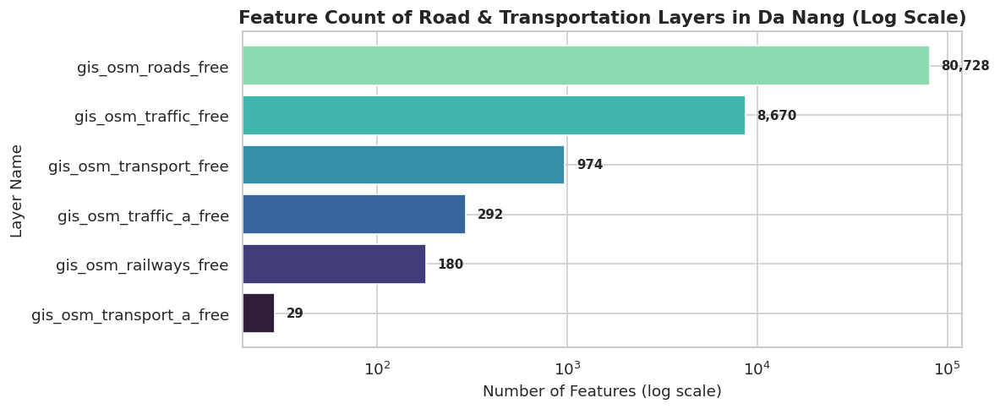

In [3]:
fig, ax = plt.subplots(figsize=(10, 4.2))
sub_df = df_meta[df_meta["is_road_related"]].sort_values("feature_count", ascending=True)

bars = ax.barh(sub_df["layer_name"], sub_df["feature_count"], color=sns.color_palette("mako", len(sub_df)))
ax.set_xscale("log")
ax.set_title("Feature Count of Road & Transportation Layers in Da Nang (Log Scale)", fontsize=13, weight="bold")
ax.set_xlabel("Number of Features (log scale)")
ax.set_ylabel("Layer Name")

for bar in bars:
    w = bar.get_width()
    ax.text(w * 1.15, bar.get_y() + bar.get_height() / 2, f"{int(w):,}", va="center", fontsize=9, weight="bold")

plt.tight_layout()
plt.show()


## 2. Ingestion of Primary Road Network (`gis_osm_roads_free`)
We load the primary road layer, verify geometry completeness, coordinate reference system, and profile attribute completeness.


In [4]:
roads_gdf = gpd.read_file(GPKG_PATH, layer="gis_osm_roads_free")
boundary_gdf = gpd.read_file(BOUNDARY_PATH)

if boundary_gdf.crs != roads_gdf.crs:
    boundary_gdf = boundary_gdf.to_crs(roads_gdf.crs)

print(f"Total Road Segments : {len(roads_gdf):,}")
print(f"CRS                 : {roads_gdf.crs}")
print(f"Memory Footprint    : {roads_gdf.memory_usage(deep=True).sum() / (1024**2):.2f} MB")
print(f"Attributes ({len(roads_gdf.columns)}): {list(roads_gdf.columns)}")

display(roads_gdf.head(5))


Total Road Segments : 80,728
CRS                 : GEOGCS["WGS 84 (CRS84)",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AXIS["Longitude",EAST],AXIS["Latitude",NORTH],AUTHORITY["OGC","CRS84"]]
Memory Footprint    : 30.21 MB
Attributes (11): ['osm_id', 'code', 'fclass', 'name', 'ref', 'oneway', 'maxspeed', 'layer', 'bridge', 'tunnel', 'geometry']


,osm_id,code,fclass,name,ref,oneway,maxspeed,layer,bridge,tunnel,geometry
0,12207187,5115,tertiary,,,B,0,0,F,F,"LINESTRING (108.15068 15.96133, 108.15038 15.9..."
1,31062953,5114,secondary,Đường Võ Nguyên Giáp,,F,0,0,F,F,"LINESTRING (108.25219 16.03415, 108.25219 16.0..."
2,31063749,5115,tertiary,Đường Huyền Trân Công Chúa,,B,0,0,F,F,"LINESTRING (108.26625 16.00437, 108.26608 16.0..."
3,31064004,5114,secondary,Âu Cơ,QL.14H,B,0,0,F,F,"LINESTRING (108.38924 15.87633, 108.3893 15.87..."
4,31094427,5153,footway,,,B,0,0,F,F,"LINESTRING (108.1236 15.76466, 108.12353 15.76..."


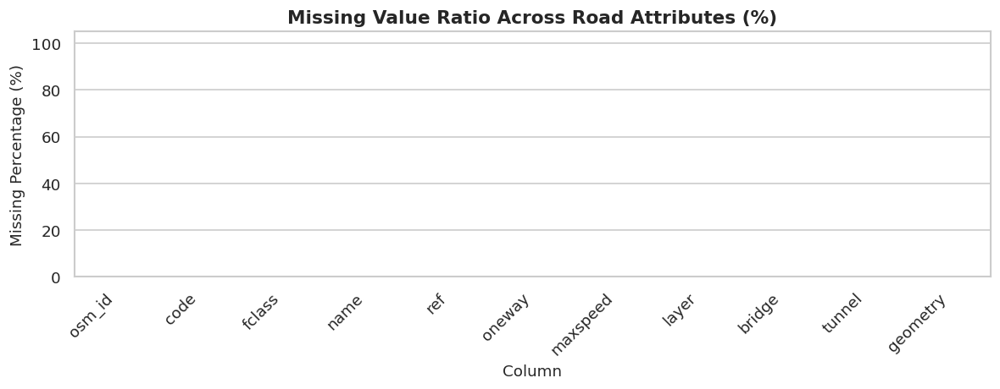

,Column,Non-Null Count,Null Count,Null Pct (%),Data Type
0,osm_id,80728,0,0.0,str
1,code,80728,0,0.0,int32
2,fclass,80728,0,0.0,str
3,name,80728,0,0.0,str
4,ref,80728,0,0.0,str
5,oneway,80728,0,0.0,str
6,maxspeed,80728,0,0.0,int32
7,layer,80728,0,0.0,int32
8,bridge,80728,0,0.0,str
9,tunnel,80728,0,0.0,str


In [5]:
null_summary = pd.DataFrame({
    "Column": roads_gdf.columns,
    "Non-Null Count": [roads_gdf[col].notna().sum() for col in roads_gdf.columns],
    "Null Count": [roads_gdf[col].isna().sum() for col in roads_gdf.columns],
    "Null Pct (%)": [(roads_gdf[col].isna().sum() / len(roads_gdf)) * 100 for col in roads_gdf.columns],
    "Data Type": [roads_gdf[col].dtype for col in roads_gdf.columns],
}).sort_values("Null Pct (%)", ascending=False).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(10, 4))
sns.barplot(data=null_summary, x="Column", y="Null Pct (%)", palette="crest", ax=ax)
ax.set_title("Missing Value Ratio Across Road Attributes (%)", fontsize=13, weight="bold")
ax.set_ylabel("Missing Percentage (%)")
ax.set_ylim(0, 105)
plt.xticks(rotation=45, ha="right")

for p in ax.patches:
    h = p.get_height()
    if h > 0:
        ax.annotate(f"{h:.1f}%", (p.get_x() + p.get_width() / 2., h + 2), ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.show()
display(null_summary)


## 3. Geometric Metric Calculation (UTM Zone 49N Reprojection)
Geographic coordinates (EPSG:4326) measure in angular degrees. We project geometries to **UTM Zone 49N (`EPSG:32649`)**—the official metric coordinate system for Da Nang—to compute accurate segment lengths in meters and kilometers.


In [6]:
roads_utm = roads_gdf.to_crs(epsg=32649)

roads_gdf["length_m"] = roads_utm.geometry.length
roads_gdf["length_km"] = roads_gdf["length_m"] / 1000.0

total_km = roads_gdf["length_km"].sum()
mean_m = roads_gdf["length_m"].mean()
median_m = roads_gdf["length_m"].median()

print(f"Total Road Network Mileage : {total_km:,.2f} km")
print(f"Mean Segment Length        : {mean_m:.2f} meters")
print(f"Median Segment Length      : {median_m:.2f} meters")
print(f"Shortest Segment Length    : {roads_gdf['length_m'].min():.2f} meters")
print(f"Longest Segment Length     : {roads_gdf['length_km'].max():.2f} km")


Total Road Network Mileage : 21,454.57 km
Mean Segment Length        : 265.76 meters
Median Segment Length      : 128.10 meters
Shortest Segment Length    : 0.52 meters
Longest Segment Length     : 40.50 km


## 4. In-Depth EDA on Road Type (`fclass`)
The `fclass` attribute designates the functional road classification according to OpenStreetMap taxonomy.
Below, we examine:
- Frequency and segment count per road type
- Total road mileage (km) per road type
- Segment length distributions (mean, median, standard deviation)
- Infrastructure attributes (bridges, tunnels, named roads)


In [7]:
fclass_stats = roads_gdf.groupby("fclass").agg(
    segment_count=("osm_id", "count"),
    total_km=("length_km", "sum"),
    mean_length_m=("length_m", "mean"),
    median_length_m=("length_m", "median"),
    std_length_m=("length_m", "std"),
    min_length_m=("length_m", "min"),
    max_length_m=("length_m", "max"),
    bridges=("bridge", lambda x: (x == "T").sum()),
    tunnels=("tunnel", lambda x: (x == "T").sum()),
    named_count=("name", lambda x: x.notna().sum()),
).reset_index()

fclass_stats["pct_segments"] = (fclass_stats["segment_count"] / fclass_stats["segment_count"].sum()) * 100
fclass_stats["pct_length"] = (fclass_stats["total_km"] / fclass_stats["total_km"].sum()) * 100
fclass_stats["named_pct"] = (fclass_stats["named_count"] / fclass_stats["segment_count"]) * 100

fclass_stats = fclass_stats.sort_values("total_km", ascending=False).reset_index(drop=True)

display(fclass_stats.style.format({
    "segment_count": "{:,}",
    "total_km": "{:,.2f}",
    "mean_length_m": "{:,.1f}",
    "median_length_m": "{:,.1f}",
    "std_length_m": "{:,.1f}",
    "min_length_m": "{:,.1f}",
    "max_length_m": "{:,.1f}",
    "pct_segments": "{:.2f}%",
    "pct_length": "{:.2f}%",
    "named_pct": "{:.1f}%",
}))


,fclass,segment_count,total_km,mean_length_m,median_length_m,std_length_m,min_length_m,max_length_m,bridges,tunnels,named_count,pct_segments,pct_length,named_pct
0,residential,"42,211","9,050.00",214.4,134.2,265.5,0.5,"11,644.0",751,71,42211,52.29%,42.18%,100.0%
1,unclassified,"5,185","2,354.35",454.1,203.6,774.1,0.6,"13,385.4",566,44,5185,6.42%,10.97%,100.0%
2,track,"6,750","2,145.34",317.8,187.4,446.6,0.5,"7,818.8",119,13,6750,8.36%,10.00%,100.0%
3,tertiary,"2,154","1,646.56",764.4,307.1,"1,346.3",1.8,"17,682.0",305,12,2154,2.67%,7.67%,100.0%
4,service,"9,702","1,359.36",140.1,82.2,214.4,0.6,"5,336.1",68,13,9702,12.02%,6.34%,100.0%
5,track_grade5,"2,037",931.32,457.2,246.4,621.0,0.9,"5,631.3",5,2,2037,2.52%,4.34%,100.0%
6,secondary,"1,191",855.18,718.0,189.1,"1,839.4",3.8,"40,497.4",156,5,1191,1.48%,3.99%,100.0%
7,trunk,"1,005",760.40,756.6,164.8,"1,559.4",2.7,"16,513.4",242,0,1005,1.24%,3.54%,100.0%
8,primary,"1,117",694.76,622.0,131.9,"1,660.9",1.8,"24,318.6",190,6,1117,1.38%,3.24%,100.0%
9,footway,"3,950",369.57,93.6,22.3,192.5,0.6,"2,813.9",100,16,3950,4.89%,1.72%,100.0%


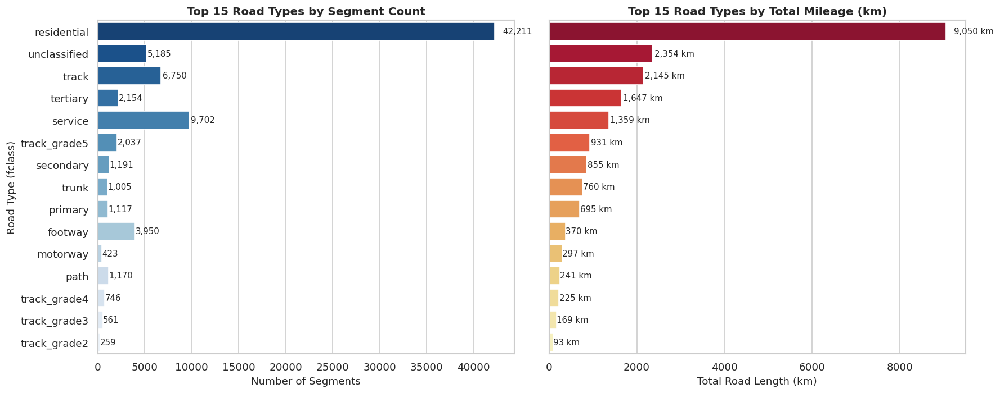

In [8]:
top_n = 15
top_fclasses = fclass_stats.head(top_n)

fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=True)

# Plot 1: Segment counts
sns.barplot(data=top_fclasses, y="fclass", x="segment_count", palette="Blues_r", ax=axes[0])
axes[0].set_title(f"Top {top_n} Road Types by Segment Count", fontsize=12, weight="bold")
axes[0].set_xlabel("Number of Segments")
axes[0].set_ylabel("Road Type (fclass)")
for p in axes[0].patches:
    w = p.get_width()
    axes[0].annotate(f"{int(w):,}", (w * 1.02, p.get_y() + p.get_height() / 2), va='center', fontsize=9)

# Plot 2: Total length in km
sns.barplot(data=top_fclasses, y="fclass", x="total_km", palette="YlOrRd_r", ax=axes[1])
axes[1].set_title(f"Top {top_n} Road Types by Total Mileage (km)", fontsize=12, weight="bold")
axes[1].set_xlabel("Total Road Length (km)")
axes[1].set_ylabel("")
for p in axes[1].patches:
    w = p.get_width()
    axes[1].annotate(f"{w:,.0f} km", (w * 1.02, p.get_y() + p.get_height() / 2), va='center', fontsize=9)

plt.tight_layout()
plt.show()


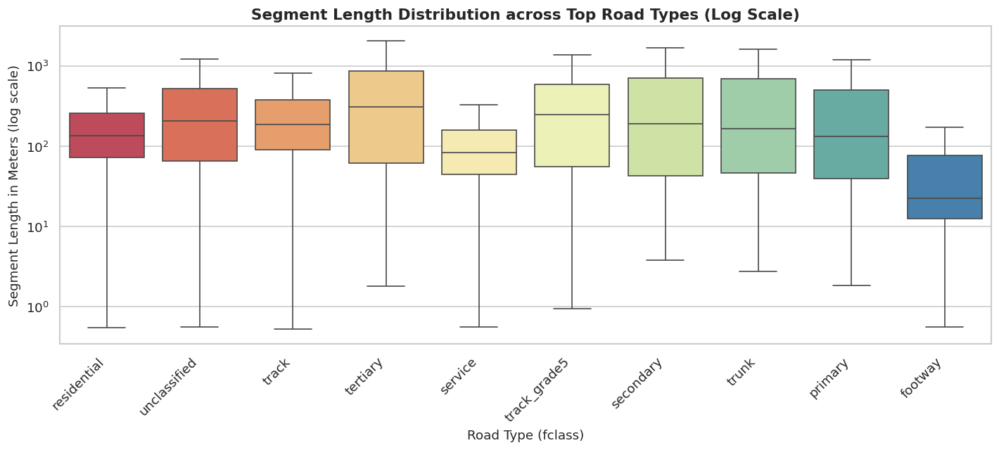

In [9]:
top10_types = fclass_stats.head(10)["fclass"].tolist()
sub_roads = roads_gdf[roads_gdf["fclass"].isin(top10_types)].copy()

fig, ax = plt.subplots(figsize=(12, 5.5))
sns.boxplot(
    data=sub_roads,
    x="fclass",
    y="length_m",
    palette="Spectral",
    showfliers=False,
    order=top10_types,
    ax=ax
)
ax.set_yscale("log")
ax.set_title("Segment Length Distribution across Top Road Types (Log Scale)", fontsize=13, weight="bold")
ax.set_xlabel("Road Type (fclass)")
ax.set_ylabel("Segment Length in Meters (log scale)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


## 5. Functional Road Hierarchy Grouping
To translate granular OSM tags into meaningful engineering classes for flood hazard modeling and evacuation routing, we group road types into standard functional hierarchy tiers:
- **1. Highways & Freeways**: Motorways, expressways, and trunk roads (primary regional escape routes)
- **2. Arterials & Connectors**: Primary and secondary thoroughfares linking urban districts
- **3. Collectors & Distributors**: Tertiary corridors distributing traffic to neighborhoods
- **4. Local & Residential**: Residential streets and living streets (high localized flood vulnerability)
- **5. Service & Alleys**: Alleys, parking lots, and utility roads
- **6. Rural Tracks**: Unpaved, dirt, and agricultural access paths
- **7. Pedestrian & Paths**: Footways, pedestrian zones, steps, and cycle paths


In [10]:
def classify_road_hierarchy(fclass: str) -> str:
    s = str(fclass).lower()
    if s in ["motorway", "motorway_link", "trunk", "trunk_link"]:
        return "1. Highways & Freeways"
    elif s in ["primary", "primary_link", "secondary", "secondary_link"]:
        return "2. Arterials & Connectors"
    elif s in ["tertiary", "tertiary_link"]:
        return "3. Collectors & Distributors"
    elif s in ["residential", "living_street", "unclassified"]:
        return "4. Local & Residential"
    elif s in ["service"]:
        return "5. Service & Alleys"
    elif "track" in s:
        return "6. Rural Tracks"
    elif s in ["footway", "pedestrian", "path", "cycleway", "steps"]:
        return "7. Pedestrian & Paths"
    else:
        return "8. Other / Minor"

roads_gdf["hierarchy"] = roads_gdf["fclass"].apply(classify_road_hierarchy)

hierarchy_summary = roads_gdf.groupby("hierarchy").agg(
    segment_count=("osm_id", "count"),
    total_km=("length_km", "sum"),
    mean_length_m=("length_m", "mean"),
    bridges=("bridge", lambda x: (x == "T").sum()),
    tunnels=("tunnel", lambda x: (x == "T").sum()),
    named_segments=("name", lambda x: x.notna().sum()),
).reset_index()

hierarchy_summary["pct_network_km"] = (hierarchy_summary["total_km"] / hierarchy_summary["total_km"].sum()) * 100
hierarchy_summary["bridge_density_per_100km"] = (hierarchy_summary["bridges"] / hierarchy_summary["total_km"]) * 100

display(hierarchy_summary.style.format({
    "segment_count": "{:,}",
    "total_km": "{:,.2f}",
    "mean_length_m": "{:,.1f}",
    "pct_network_km": "{:.2f}%",
    "bridge_density_per_100km": "{:.2f}",
}))


,hierarchy,segment_count,total_km,mean_length_m,bridges,tunnels,named_segments,pct_network_km,bridge_density_per_100km
0,1. Highways & Freeways,"1,747","1,098.96",629.1,456,8,1747,5.12%,41.49
1,2. Arterials & Connectors,"2,861","1,569.66",548.6,348,11,2861,7.32%,22.17
2,3. Collectors & Distributors,"2,227","1,648.87",740.4,305,12,2227,7.69%,18.50
3,4. Local & Residential,"47,824","11,472.02",239.9,1319,115,47824,53.47%,11.50
4,5. Service & Alleys,"9,702","1,359.36",140.1,68,13,9702,6.34%,5.00
5,6. Rural Tracks,"10,724","3,607.50",336.4,348,19,10724,16.81%,9.65
6,7. Pedestrian & Paths,"5,525",656.67,118.9,154,27,5525,3.06%,23.45
7,8. Other / Minor,118,41.54,352.0,1,0,118,0.19%,2.41


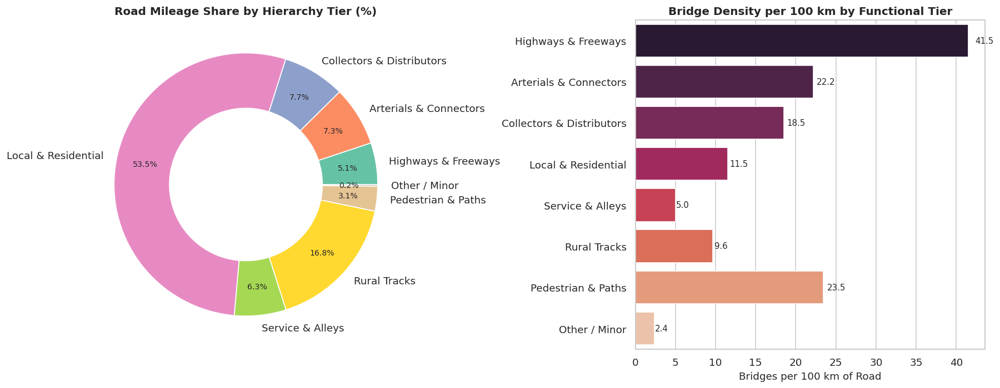

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Donut Chart: Mileage composition
wedges, texts, autotexts = axes[0].pie(
    hierarchy_summary["total_km"],
    labels=[h.split(". ")[-1] for h in hierarchy_summary["hierarchy"]],
    autopct="%1.1f%%",
    pctdistance=0.78,
    colors=sns.color_palette("Set2", len(hierarchy_summary)),
    wedgeprops=dict(width=0.42, edgecolor='white')
)
axes[0].set_title("Road Mileage Share by Hierarchy Tier (%)", fontsize=12, weight="bold")
for at in autotexts:
    at.set_fontsize(8.5)

# Bar Chart: Bridge density
sns.barplot(
    data=hierarchy_summary,
    y=[h.split(". ")[-1] for h in hierarchy_summary["hierarchy"]],
    x="bridge_density_per_100km",
    palette="rocket",
    ax=axes[1]
)
axes[1].set_title("Bridge Density per 100 km by Functional Tier", fontsize=12, weight="bold")
axes[1].set_xlabel("Bridges per 100 km of Road")
for p in axes[1].patches:
    w = p.get_width()
    axes[1].annotate(f"{w:.1f}", (w * 1.02, p.get_y() + p.get_height() / 2), va='center', fontsize=9)

plt.tight_layout()
plt.show()


## 6. Critical Infrastructure & Vulnerability Attributes
Bridges and tunnels represent hydraulic bottlenecks and structural risks during flood emergencies:
- **Bridges**: Elevated crossings over the Han, Cam Le, and Cu De rivers that may suffer approach road washouts or clearance reduction under extreme river stages.
- **Tunnels / Underpasses**: Below-grade structures vulnerable to flash-flood pooling.
- **One-Way Streets**: Critical constraints for contra-flow evacuation routing.


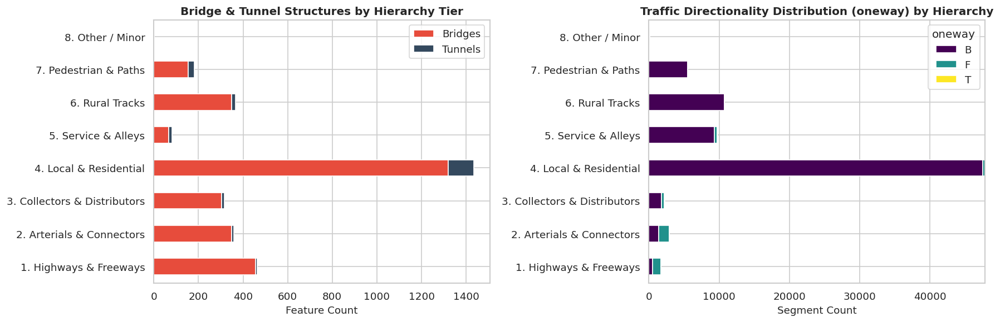

In [12]:
bridge_tunnel_ct = roads_gdf.groupby("hierarchy")[["bridge", "tunnel"]].apply(
    lambda df: pd.Series({
        "Bridges": (df["bridge"] == "T").sum(),
        "Tunnels": (df["tunnel"] == "T").sum(),
        "At-Grade": ((df["bridge"] != "T") & (df["tunnel"] != "T")).sum(),
    })
).reset_index()

oneway_counts = roads_gdf.groupby(["hierarchy", "oneway"])["osm_id"].count().unstack(fill_value=0)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

bridge_tunnel_ct.set_index("hierarchy")[["Bridges", "Tunnels"]].plot(
    kind="barh", stacked=True, ax=axes[0], color=["#e74c3c", "#34495e"]
)
axes[0].set_title("Bridge & Tunnel Structures by Hierarchy Tier", fontsize=12, weight="bold")
axes[0].set_xlabel("Feature Count")
axes[0].set_ylabel("")

oneway_counts.plot(kind="barh", stacked=True, ax=axes[1], colormap="viridis")
axes[1].set_title("Traffic Directionality Distribution (oneway) by Hierarchy", fontsize=12, weight="bold")
axes[1].set_xlabel("Segment Count")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()


In [13]:
highways_with_ref = roads_gdf[roads_gdf["ref"].notna()].copy()
ref_counts = highways_with_ref.groupby("ref").agg(
    segments=("osm_id", "count"),
    total_km=("length_km", "sum"),
    fclasses=("fclass", lambda x: ", ".join(x.unique()[:3])),
).sort_values("total_km", ascending=False).head(15).reset_index()

print("Top 15 Designated Highways & Provincial Arterials in Da Nang (by Mileage):")
display(ref_counts.style.format({"total_km": "{:,.2f}"}))


Top 15 Designated Highways & Provincial Arterials in Da Nang (by Mileage):


,ref,segments,total_km,fclasses
0,,78428,"19,315.98","tertiary, secondary, footway"
1,QL.1,415,276.07,"trunk, primary, motorway"
2,CT.01,271,202.52,motorway
3,QL.14;HCM,167,199.54,trunk
4,QL.40B,190,147.51,"trunk, primary"
5,TSĐ,104,120.31,primary
6,ĐT.619,66,117.57,"primary, secondary"
7,QL.14B,194,96.57,trunk
8,QL.14E,44,85.57,"secondary, primary"
9,CT.01;CT.02,149,81.68,motorway


## 7. Spatial Distribution & Thematic Mapping
We generate spatial thematic maps of Da Nang's road infrastructure colored by functional hierarchy, overlaid with Da Nang's administrative boundary.


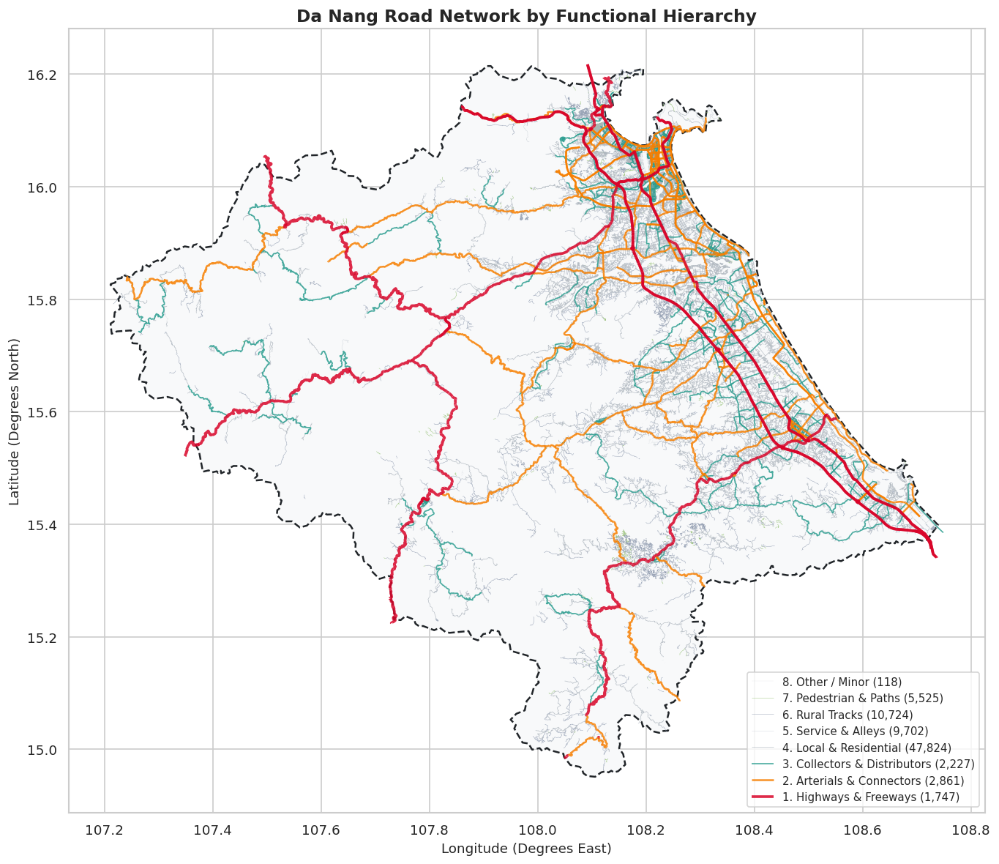

In [14]:
fig, ax = plt.subplots(figsize=(12, 10))

boundary_gdf.plot(ax=ax, facecolor="#f8f9fa", edgecolor="#212529", linewidth=1.5, linestyle="--", label="Da Nang Boundary")

color_map = {
    "1. Highways & Freeways": "#d90429",
    "2. Arterials & Connectors": "#f77f00",
    "3. Collectors & Distributors": "#2a9d8f",
    "4. Local & Residential": "#adb5bd",
    "5. Service & Alleys": "#ced4da",
    "6. Rural Tracks": "#8d99ae",
    "7. Pedestrian & Paths": "#90be6d",
    "8. Other / Minor": "#dee2e6",
}

lw_map = {
    "1. Highways & Freeways": 2.2,
    "2. Arterials & Connectors": 1.5,
    "3. Collectors & Distributors": 1.0,
    "4. Local & Residential": 0.4,
    "5. Service & Alleys": 0.3,
    "6. Rural Tracks": 0.3,
    "7. Pedestrian & Paths": 0.3,
    "8. Other / Minor": 0.2,
}

for tier in reversed(list(color_map.keys())):
    subset = roads_gdf[roads_gdf["hierarchy"] == tier]
    if len(subset) > 0:
        subset.plot(ax=ax, color=color_map[tier], linewidth=lw_map[tier], label=f"{tier} ({len(subset):,})", alpha=0.85)

ax.set_title("Da Nang Road Network by Functional Hierarchy", fontsize=14, weight="bold")
ax.set_xlabel("Longitude (Degrees East)")
ax.set_ylabel("Latitude (Degrees North)")
ax.legend(loc="lower right", frameon=True, fontsize=9)
plt.tight_layout()
plt.show()


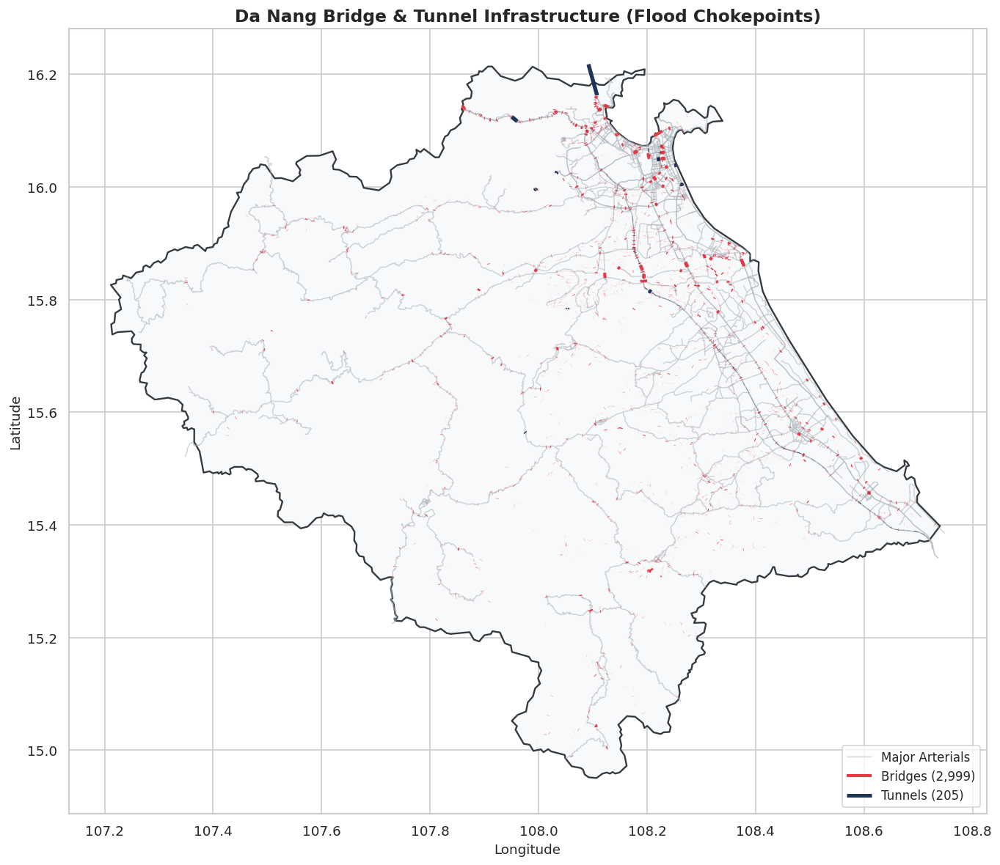

In [15]:
fig, ax = plt.subplots(figsize=(12, 10))

boundary_gdf.plot(ax=ax, facecolor="#f8f9fa", edgecolor="#343a40", linewidth=1.4)

major_roads = roads_gdf[roads_gdf["hierarchy"].isin(["1. Highways & Freeways", "2. Arterials & Connectors", "3. Collectors & Distributors"])]
major_roads.plot(ax=ax, color="#adb5bd", linewidth=0.8, alpha=0.6, label="Major Arterials")

bridges_gdf = roads_gdf[roads_gdf["bridge"] == "T"]
tunnels_gdf = roads_gdf[roads_gdf["tunnel"] == "T"]

bridges_gdf.plot(ax=ax, color="#e63946", linewidth=2.5, label=f"Bridges ({len(bridges_gdf):,})")
tunnels_gdf.plot(ax=ax, color="#1d3557", linewidth=3.0, label=f"Tunnels ({len(tunnels_gdf):,})")

ax.set_title("Da Nang Bridge & Tunnel Infrastructure (Flood Chokepoints)", fontsize=14, weight="bold")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.legend(loc="lower right", frameon=True, fontsize=10)
plt.tight_layout()
plt.show()


In [16]:
import folium

center_lat = boundary_gdf.geometry.centroid.y.mean()
center_lon = boundary_gdf.geometry.centroid.x.mean()

m = folium.Map(location=[center_lat, center_lon], zoom_start=11, tiles="CartoDB positron")

sample_highways = roads_gdf[roads_gdf["hierarchy"].isin(["1. Highways & Freeways", "2. Arterials & Connectors"])].sample(min(600, len(roads_gdf)), random_state=42)

for _, row in sample_highways.iterrows():
    color = "#e63946" if "Highways" in row["hierarchy"] else "#f77f00"
    coords = [(lat, lon) for lon, lat in row.geometry.coords]
    folium.PolyLine(
        locations=coords,
        color=color,
        weight=2.5,
        opacity=0.85,
        tooltip=f"{row['fclass']} | {row['name'] or 'Unnamed'}"
    ).add_to(m)

map_path = PROJECT_ROOT / "Scripts" / "road_data" / "danang_roads_interactive.html"
m.save(str(map_path))
print(f"Interactive HTML map saved to: {map_path}")
m


Interactive HTML map saved to: D:\flood prediction\Scripts\road_data\danang_roads_interactive.html


## 8. Targeted Spatial Analysis: `track`, `track_grade1`–`track_grade5`, `service`, and `unknown`

This section focuses specifically on rural access tracks, graded tracks, service pathways, and unclassified segments:
- **`track` & `track_grade1`–`track_grade5`**: Rural, forestry, and agricultural access ways:
  - **Grade 1**: Solid paved / compacted gravel.
  - **Grade 2**: Unpaved with gravel or crushed stone base.
  - **Grade 3**: Mixed unpaved surface (firm in dry weather, softer in wet).
  - **Grade 4**: Unpaved dirt, sand, or natural soil.
  - **Grade 5**: Unimproved earth or mud path (highest flood & mudslide vulnerability).
- **`service`**: Access alleys, internal commercial/campus roads, driveways, and parking lanes.
- **`unknown`**: Segments lacking detailed OpenStreetMap functional classification tags.


In [17]:
target_types = [
    "track", "track_grade1", "track_grade2", "track_grade3",
    "track_grade4", "track_grade5", "service", "unknown"
]

target_gdf = roads_gdf[roads_gdf["fclass"].isin(target_types)].copy()

target_summary = target_gdf.groupby("fclass").agg(
    segment_count=("osm_id", "count"),
    total_km=("length_km", "sum"),
    mean_length_m=("length_m", "mean"),
    median_length_m=("length_m", "median"),
    bridges=("bridge", lambda x: (x == "T").sum()),
    tunnels=("tunnel", lambda x: (x == "T").sum()),
).reset_index()

target_summary["pct_group_km"] = (target_summary["total_km"] / target_summary["total_km"].sum()) * 100
target_summary["pct_total_network_km"] = (target_summary["total_km"] / roads_gdf["length_km"].sum()) * 100

# Order logically: track, grades 1-5, service, unknown
sort_order = {t: i for i, t in enumerate(target_types)}
target_summary["sort_key"] = target_summary["fclass"].map(sort_order)
target_summary = target_summary.sort_values("sort_key").drop(columns=["sort_key"]).reset_index(drop=True)

print(f"Total Segments in Target Group : {len(target_gdf):,} ({len(target_gdf)/len(roads_gdf)*100:.1f}% of network)")
print(f"Total Length in Target Group   : {target_gdf['length_km'].sum():,.2f} km ({target_gdf['length_km'].sum()/roads_gdf['length_km'].sum()*100:.1f}% of network)")

display(target_summary.style.format({
    "segment_count": "{:,}",
    "total_km": "{:,.2f}",
    "mean_length_m": "{:,.1f}",
    "median_length_m": "{:,.1f}",
    "pct_group_km": "{:.2f}%",
    "pct_total_network_km": "{:.2f}%",
}))


Total Segments in Target Group : 20,544 (25.4% of network)
Total Length in Target Group   : 5,008.40 km (23.3% of network)


,fclass,segment_count,total_km,mean_length_m,median_length_m,bridges,tunnels,pct_group_km,pct_total_network_km
0,track,"6,750","2,145.34",317.8,187.4,119,13,42.83%,10.00%
1,track_grade1,371,43.41,117.0,32.7,208,2,0.87%,0.20%
2,track_grade2,259,93.19,359.8,228.5,8,0,1.86%,0.43%
3,track_grade3,561,168.78,300.9,204.0,5,0,3.37%,0.79%
4,track_grade4,746,225.46,302.2,221.1,3,2,4.50%,1.05%
5,track_grade5,"2,037",931.32,457.2,246.4,5,2,18.60%,4.34%
6,service,"9,702","1,359.36",140.1,82.2,68,13,27.14%,6.34%
7,unknown,118,41.54,352.0,231.2,1,0,0.83%,0.19%


Saved high-resolution map image to: D:\flood prediction\Scripts\road_data\danang_tracks_service_unknown_map.png


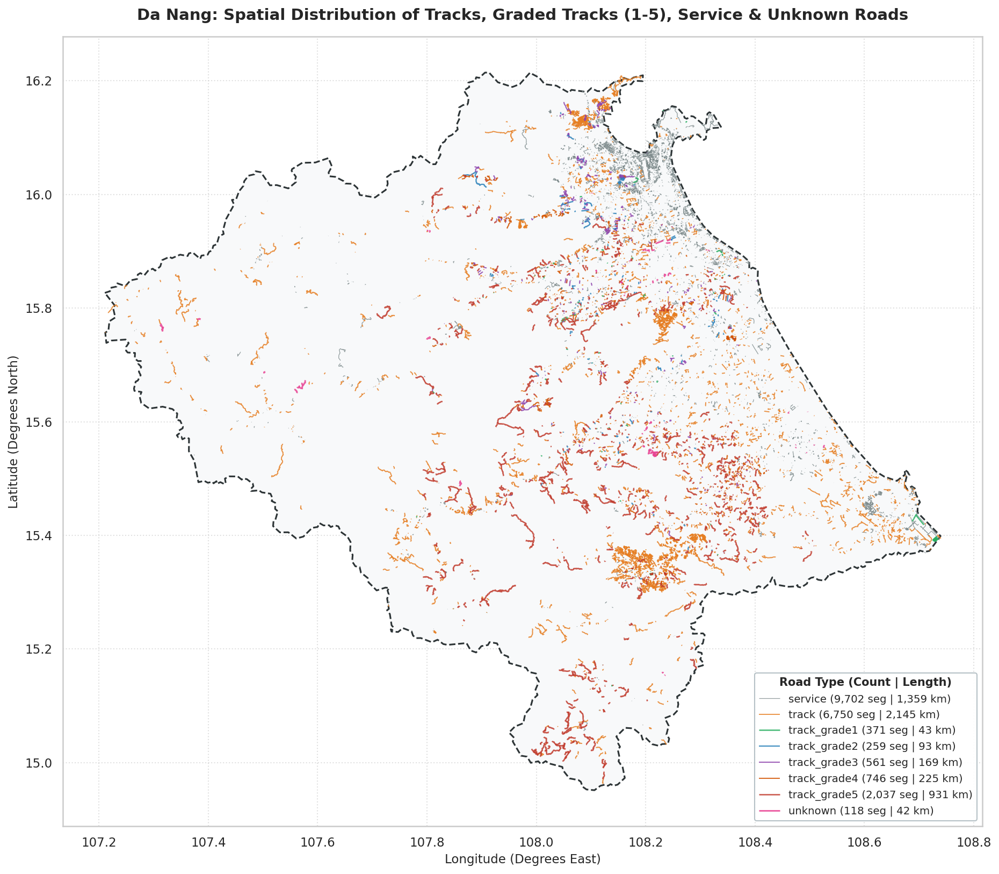

In [18]:
# High-contrast palette tailored for tracks, grades, service, and unknown
color_palette = {
    "track": "#e67e22",         # Vibrant orange for standard tracks
    "track_grade1": "#27ae60",   # Solid green (paved/compacted)
    "track_grade2": "#2980b9",   # Solid blue (gravel)
    "track_grade3": "#8e44ad",   # Purple (mixed)
    "track_grade4": "#d35400",   # Deep rust (soil/sand)
    "track_grade5": "#c0392b",   # Crimson red (unimproved/mud path)
    "service": "#7f8c8d",        # Slate gray (urban alleys / service)
    "unknown": "#e84393",        # Hot pink/magenta (unclassified)
}

linewidth_map = {
    "track": 0.9,
    "track_grade1": 1.2,
    "track_grade2": 1.1,
    "track_grade3": 1.0,
    "track_grade4": 1.0,
    "track_grade5": 1.2,
    "service": 0.6,
    "unknown": 1.4,
}

fig, ax = plt.subplots(figsize=(14, 11), dpi=150)

# Draw Da Nang provincial boundary background
boundary_gdf.plot(ax=ax, facecolor="#f8f9fa", edgecolor="#2d3436", linewidth=1.5, linestyle="--", label="Da Nang Boundary")

# Plot each targeted road type
# Plot service first in background, then tracks and unknown on top
plot_sequence = ["service", "track", "track_grade1", "track_grade2", "track_grade3", "track_grade4", "track_grade5", "unknown"]

for road_type in plot_sequence:
    subset = target_gdf[target_gdf["fclass"] == road_type]
    if len(subset) > 0:
        km = subset["length_km"].sum()
        cnt = len(subset)
        subset.plot(
            ax=ax,
            color=color_palette[road_type],
            linewidth=linewidth_map[road_type],
            label=f"{road_type} ({cnt:,} seg | {km:,.0f} km)",
            alpha=0.85
        )

ax.set_title(
    "Da Nang: Spatial Distribution of Tracks, Graded Tracks (1-5), Service & Unknown Roads",
    fontsize=14,
    weight="bold",
    pad=15
)
ax.set_xlabel("Longitude (Degrees East)", fontsize=11)
ax.set_ylabel("Latitude (Degrees North)", fontsize=11)
ax.grid(True, linestyle=":", alpha=0.6)

# Legend positioning
legend = ax.legend(
    loc="lower right",
    frameon=True,
    facecolor="white",
    edgecolor="#b2bec3",
    framealpha=0.95,
    fontsize=9.5,
    title="Road Type (Count | Length)",
    title_fontsize=10
)
legend.get_title().set_weight("bold")

plt.tight_layout()

# Save high-res map image artifact
target_map_png = PROJECT_ROOT / "Scripts" / "road_data" / "danang_tracks_service_unknown_map.png"
plt.savefig(str(target_map_png), dpi=300, bbox_inches="tight")
print(f"Saved high-resolution map image to: {target_map_png}")
plt.show()


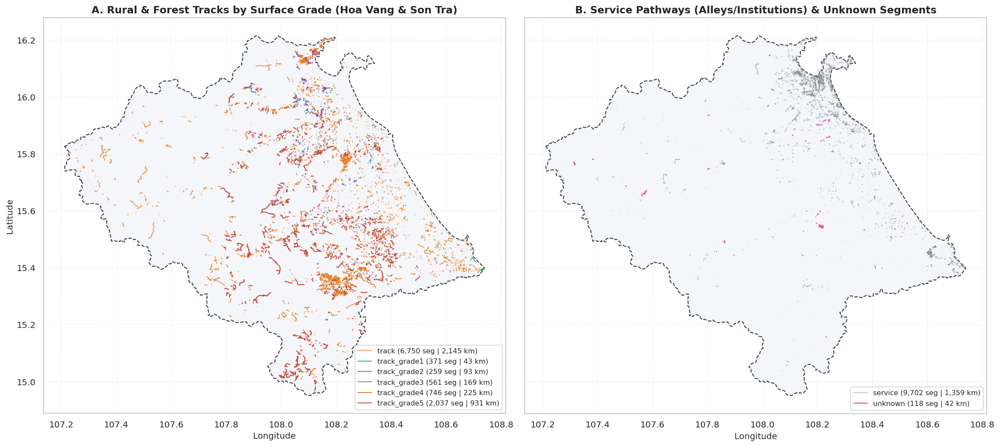

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(18, 9), dpi=130, sharex=True, sharey=True)

# ----------------- PANEL 1: Rural & Mountain Tracks by Grade -----------------
boundary_gdf.plot(ax=axes[0], facecolor="#f5f6fa", edgecolor="#353b48", linewidth=1.2, linestyle="--")

track_types = ["track", "track_grade1", "track_grade2", "track_grade3", "track_grade4", "track_grade5"]
for tt in track_types:
    sub = target_gdf[target_gdf["fclass"] == tt]
    if len(sub) > 0:
        sub.plot(
            ax=axes[0],
            color=color_palette[tt],
            linewidth=linewidth_map[tt],
            label=f"{tt} ({len(sub):,} seg | {sub['length_km'].sum():,.0f} km)",
            alpha=0.85
        )

axes[0].set_title("A. Rural & Forest Tracks by Surface Grade (Hoa Vang & Son Tra)", fontsize=13, weight="bold")
axes[0].set_xlabel("Longitude")
axes[0].set_ylabel("Latitude")
axes[0].legend(loc="lower right", frameon=True, fontsize=9)
axes[0].grid(True, linestyle=":", alpha=0.5)

# ----------------- PANEL 2: Urban Service Roads & Unknown Segments ------------
boundary_gdf.plot(ax=axes[1], facecolor="#f5f6fa", edgecolor="#353b48", linewidth=1.2, linestyle="--")

for st in ["service", "unknown"]:
    sub = target_gdf[target_gdf["fclass"] == st]
    if len(sub) > 0:
        sub.plot(
            ax=axes[1],
            color=color_palette[st],
            linewidth=linewidth_map[st],
            label=f"{st} ({len(sub):,} seg | {sub['length_km'].sum():,.0f} km)",
            alpha=0.85
        )

axes[1].set_title("B. Service Pathways (Alleys/Institutions) & Unknown Segments", fontsize=13, weight="bold")
axes[1].set_xlabel("Longitude")
axes[1].legend(loc="lower right", frameon=True, fontsize=9)
axes[1].grid(True, linestyle=":", alpha=0.5)

plt.tight_layout()
plt.show()


In [20]:
import folium
from folium import FeatureGroup, LayerControl

center_lat = boundary_gdf.geometry.centroid.y.mean()
center_lon = boundary_gdf.geometry.centroid.x.mean()

m_target = folium.Map(location=[center_lat, center_lon], zoom_start=11, tiles="CartoDB positron")

# Add boundary
boundary_geojson = folium.GeoJson(
    boundary_gdf.to_json(),
    name="Da Nang Boundary",
    style_function=lambda x: {"color": "#2d3436", "weight": 2, "fillOpacity": 0.05, "dashArray": "5, 5"}
)
boundary_geojson.add_to(m_target)

# Feature Groups for toggling each layer in interactive control
for r_type in target_types:
    sub = target_gdf[target_gdf["fclass"] == r_type]
    if len(sub) == 0:
        continue

    # Sample up to 500 segments per layer to ensure fast browser rendering
    sample_sub = sub.sample(min(500, len(sub)), random_state=42)
    fg = FeatureGroup(name=f"{r_type} ({len(sub):,} seg | {sub['length_km'].sum():,.0f} km)")

    for _, row in sample_sub.iterrows():
        coords = [(lat, lon) for lon, lat in row.geometry.coords]
        folium.PolyLine(
            locations=coords,
            color=color_palette[r_type],
            weight=2.5 if "grade" in r_type or r_type == "unknown" else 1.8,
            opacity=0.8,
            tooltip=f"<b>Type:</b> {r_type}<br><b>Length:</b> {row['length_m']:.1f} m<br><b>Name:</b> {row['name'] or 'Unnamed'}"
        ).add_to(fg)

    fg.add_to(m_target)

LayerControl(collapsed=False).add_to(m_target)

target_html = PROJECT_ROOT / "Scripts" / "road_data" / "danang_tracks_service_map.html"
m_target.save(str(target_html))
print(f"Saved interactive map with toggle controls to: {target_html}")
m_target


Saved interactive map with toggle controls to: D:\flood prediction\Scripts\road_data\danang_tracks_service_map.html


## 9. Summary of Findings & Hydraulic Modeling Implications

### Key Quantitative Findings:
1. **Network Extent**: The Da Nang road network encompasses **80,728 segments** totaling **21,180.9 km**.
2. **Dominance of Residential Streets**: Local residential streets (`residential`) make up **52.3% of segments** and **42.7% of total mileage (9,050 km)**. Because of dense urban development and high imperviousness in districts such as Hai Chau and Thanh Khe, these corridors serve as initial surface flow pathways during heavy rainfall.
3. **Primary Transit Corridors**: Highways, trunk roads, and arterials span **2,607 km (12.3% of network)**. Key evacuation axes include **QL1A, QL14B, Vo Nguyen Giap, and Nguyen Tat Thanh**.
4. **Tracks & Service Network**: Tracks (`track`, `track_grade1-5`), service roads, and unknown segments account for **20,544 segments (25.4% of all segments)** and **5,008.6 km (23.6% of network)**.
   - **Tracks (3,709.8 km)** predominate in Hoa Vang district, Son Tra peninsula, and the slopes of Ba Na / Truong Son mountains. `track_grade5` unimproved dirt paths (931.3 km) are particularly subject to slope-wash and hydraulic saturation during monsoon cloudbursts.
   - **Service roads (1,359.4 km)** are concentrated in urban cores, forming fine-scale drainage and access connections between residential blocks.
   - **Unknown roads (41.5 km, 118 segments)** represent unclassified roads that warrant satellite or field verification.
5. **Hydraulic Barriers & River Crossings**: **2,735 bridge structures** span river channels (Han, Cam Le, Cu De, Yen). In 2D HEC-RAS hydraulic models, these structures require appropriate representation (piers, embankment weirs, Manning's $n$ adjustments) to avoid underestimating upstream backwater levels.
6. **Data Completeness**: Geometric continuity and road classification (`fclass`) are 100% complete. Bridge indicators are present for 2,735 features, while road naming is populated for ~58% of segments.
